# Financial Risk Modelling Under Different Distributional Assumptions
## How sensitive are portfolio risk estimates to assumptions about financial returns?

A completed statistical modelling portfolio project. This is a demonstration of established probability, simulation and backtesting methods, not a claim of novel research or an investment recommendation.

**Data:** Kenneth French daily returns for six size/book-to-market equity research portfolios. **Allocation:** one sixth to each sleeve at the start of each trading day. **Training:** 2010–2019. **Out-of-sample evaluation:** 2020–2024.

Run `python src/run_analysis.py --bootstrap 250 --paths 200000` to regenerate all outputs. This executed notebook walks through the data, fitted models and saved experiment outputs without silently rerunning 250 bootstraps.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src/run_analysis.py').exists(), 'Start Jupyter from the project root or notebook directory.'
sys.path.insert(0,str(ROOT/'src'))
from run_analysis import load_returns, WEIGHTS, TRAIN_START, TRAIN_END
from risk import fit_distributions, model_risk, empirical_risk
reports=ROOT/'reports'
data,audit=load_returns()
train=data.loc[TRAIN_START:TRAIN_END,'portfolio'].to_numpy()
fit=fit_distributions(train)
display(audit)
display(data.head())
display(dict(zip(data.columns[:6],WEIGHTS)))

{'raw_daily_rows': 26317,
 'selected_complete_rows': 3774,
 'missing_rows_removed': 0,
 'source_header': 'This file was created by using the 202608 CRSP database.'}

,SMALL LoBM,ME1 BM2,SMALL HiBM,BIG LoBM,ME2 BM2,BIG HiBM,portfolio
date,,,,,,,
2010-01-04,0.0217,0.0234,0.0311,0.0135,0.0176,0.0268,0.022350
2010-01-05,-0.0030,-0.0014,0.0049,-0.0009,0.0052,0.0155,0.003383
2010-01-06,-0.0012,0.0008,0.0019,-0.0006,0.0018,0.0073,0.001667
2010-01-07,0.0044,0.0063,0.0108,-0.0004,0.0070,0.0123,0.006733
2010-01-08,0.0029,0.0056,0.0084,0.0037,0.0039,-0.0014,0.003850


{'SMALL LoBM': 0.16666666666666666,
 'ME1 BM2': 0.16666666666666666,
 'SMALL HiBM': 0.16666666666666666,
 'BIG LoBM': 0.16666666666666666,
 'ME2 BM2': 0.16666666666666666,
 'BIG HiBM': 0.16666666666666666}

## 1. Data quality, units and EDA
The source contains multiple tables. The parser selects the **average value-weighted daily returns** section only. It removes provider missing-value markers before dividing source percentage points by 100. Dates remain ordered, with no forward filling.

Within each research sleeve the provider uses value weights; the project's cross-sleeve allocation is equal. These are historical academic equity portfolios, not six ETFs or an investable fund. Return series are supplied directly, so no price-adjustment or risk-free-return calculation is required.

,period,n,mean,std,skew,excess_kurtosis,minimum,maximum,return_acf1,absolute_return_acf1
0,Training 2010–2019,2516,0.00054,0.01085,-0.35569,3.94827,-0.07967,0.05708,-0.04232,0.19173
1,Test 2020–2024,1258,0.00057,0.01565,-0.60804,10.19185,-0.12957,0.10157,-0.12725,0.35424


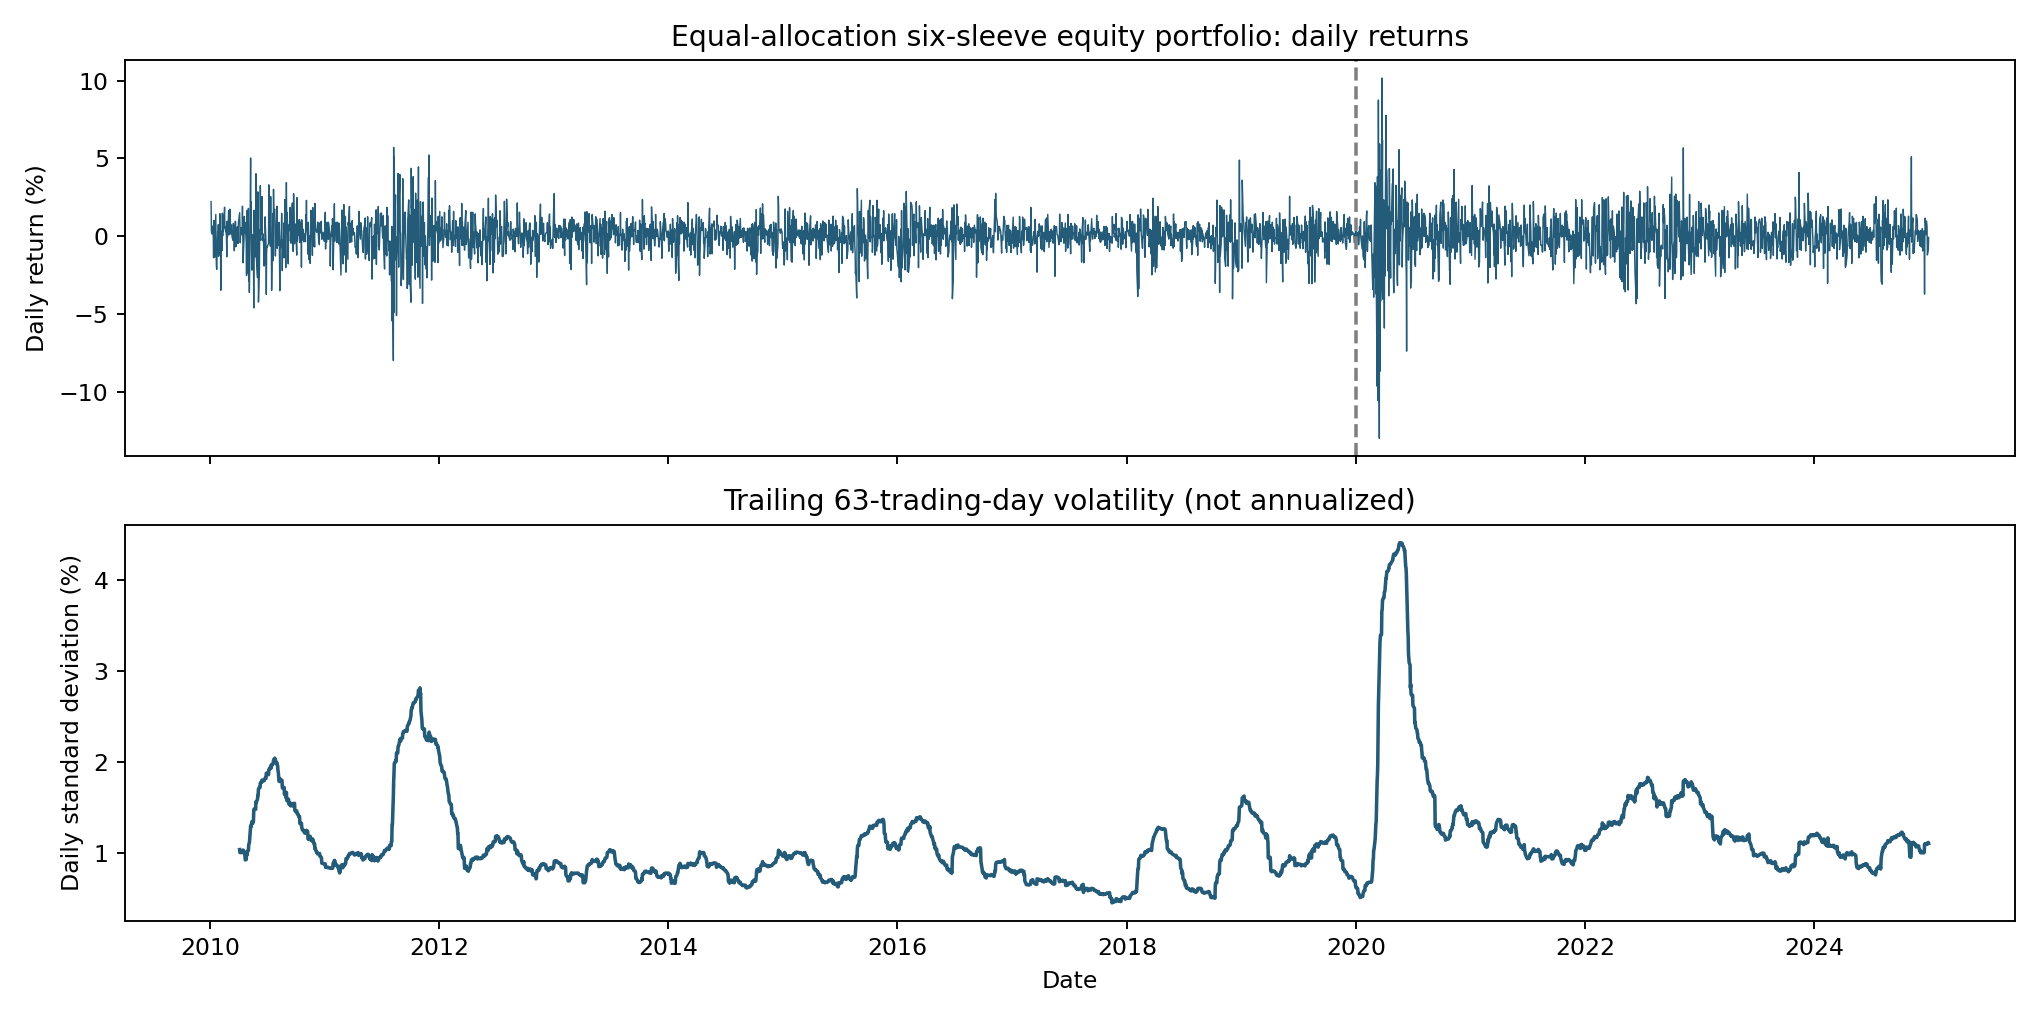

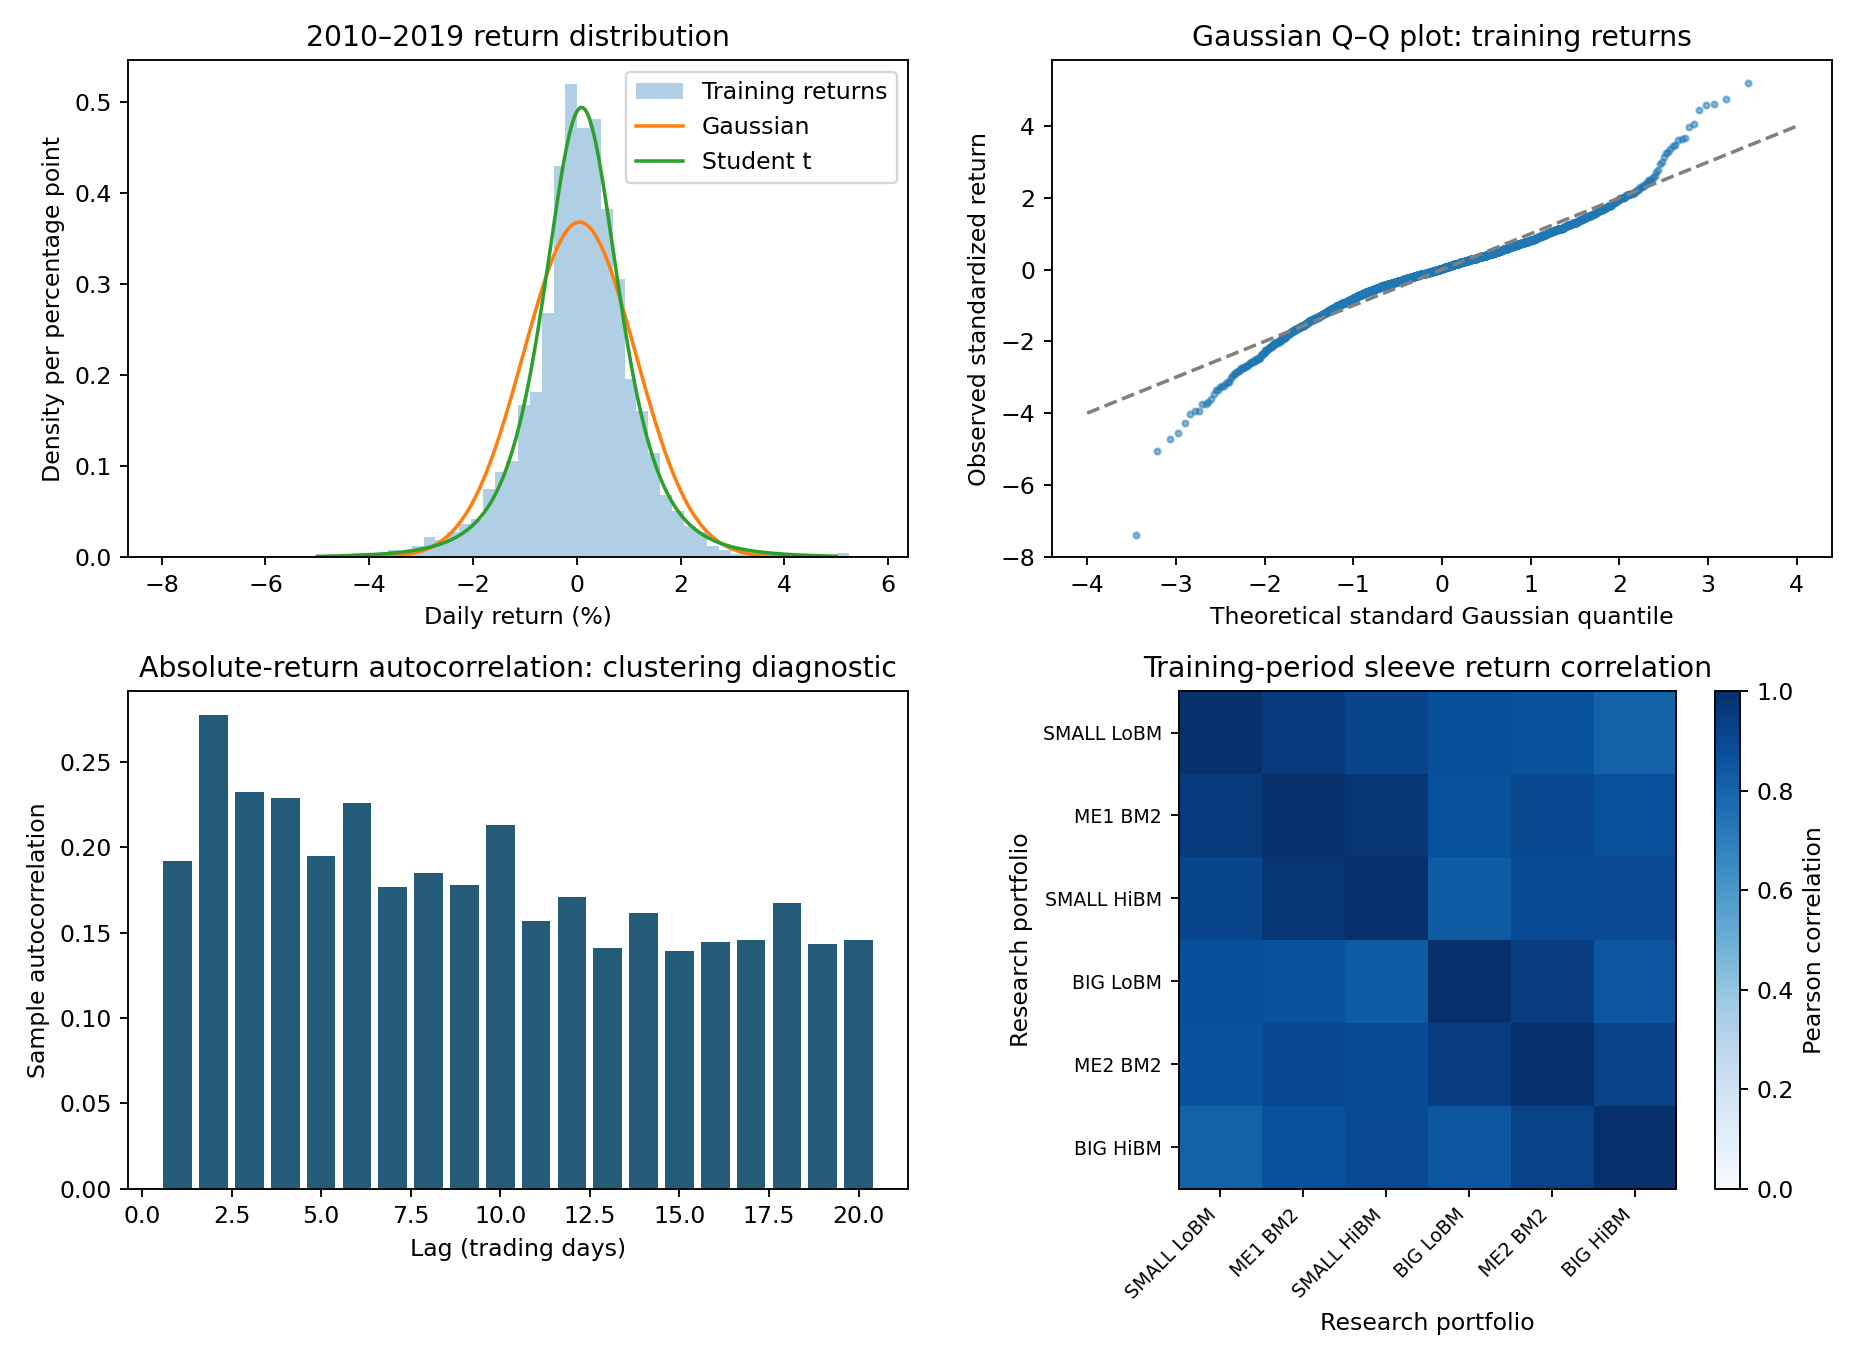

In [2]:
display(pd.read_csv(reports/'eda_summary.csv').round(5))
display(Image(filename=str(reports/'figures/return_history.png')))
display(Image(filename=str(reports/'figures/distribution_diagnostics.png')))

## 2. Probability models and mathematical definitions
Let $r_t$ be daily portfolio return and $L_t=-r_t$ the daily loss fraction. Positive values denote losses. For confidence level $\alpha$,

$$\operatorname{VaR}_\alpha(L)=F_L^{-1}(\alpha),\qquad
\operatorname{ES}_\alpha(L)=\frac{1}{1-\alpha}\int_\alpha^1 F_L^{-1}(u)\,du.$$

We compare:

- **Gaussian:** $r\sim N(\mu,\sigma^2)$, with maximum-likelihood mean and standard deviation.
- **Student's t:** $r=\ell+sT_\nu$, fitted by constrained maximum likelihood with $2.05\leq\nu\leq200$. Finite variance is imposed; scale is not standard deviation. The Gaussian and t fits need not share moments.
- **Historical:** an empirical distribution of training returns. It retains observed asymmetry but cannot extrapolate beyond its largest observed loss.

Gaussian loss ES is $-\mu+\sigma\phi(z_\alpha)/(1-\alpha)$. Student t loss ES is $-\ell+s(\nu+q_\alpha^2)t_\nu(q_\alpha)/[(\nu-1)(1-\alpha)]$. Historical ES includes a fractional threshold observation when required by the quantile integral. Simply averaging losses strictly above a discrete VaR can give the wrong answer.

In [3]:
display(fit)
for name in ['Gaussian','Student t','Historical']:
    v,e=model_risk(name,fit,train,.99)
    print(f'{name}: 99% one-day VaR = {100*v:.3f}%; ES = {100*e:.3f}%')
print('Discrete example: losses 1,2,3,4,5 at alpha=0.7 ->',empirical_risk([1,2,3,4,5],.7))

DistributionFit(mean=0.0005376854795972443, sigma=0.010845106070274203, t_df=3.5864394524286762, t_location=0.0009271938402115576, t_scale=0.007543063418666534, t_optimizer_success=True)

Gaussian: 99% one-day VaR = 2.469%; ES = 2.837%
Student t: 99% one-day VaR = 2.922%; ES = 4.249%
Historical: 99% one-day VaR = 3.033%; ES = 4.010%
Discrete example: losses 1,2,3,4,5 at alpha=0.7 -> (4.0, 4.666666666666667)


## 3. One-day risk and estimation uncertainty
The risk table uses exact fitted-distribution formulas rather than relying on simulation. Percentile intervals come from **250 circular moving-block bootstrap samples**, with block length ten trading days. Each replicate refits both parametric distributions.

These intervals address sampling uncertainty under the selected resampling design. They do not encompass future regime changes, provider data revisions, or uncertainty about which distribution is appropriate. Dollar illustrations assume a hypothetical $100,000 notional.

,model,alpha,var,es,var_per_100k,es_per_100k,var_ci_lo,var_ci_hi,es_ci_lo,es_ci_hi
0,Gaussian,0.95,0.01730,0.02183,1730.09266,2183.26537,0.01574,0.01887,0.01994,0.02374
1,Gaussian,0.99,0.02469,0.02837,2469.18040,2836.68454,0.02258,0.02682,0.02598,0.03074
2,Student t,0.95,0.01570,0.02480,1570.13227,2480.43066,0.01443,0.01666,0.02224,0.02756
3,Student t,0.99,0.02922,0.04249,2922.48284,4248.80688,0.02617,0.03241,0.03576,0.04933
4,Historical,0.95,0.01737,0.02612,1736.66667,2611.71966,0.01586,0.01908,0.02322,0.02914
5,Historical,0.99,0.03033,0.04010,3033.33333,4010.47960,0.02775,0.03463,0.03403,0.04764


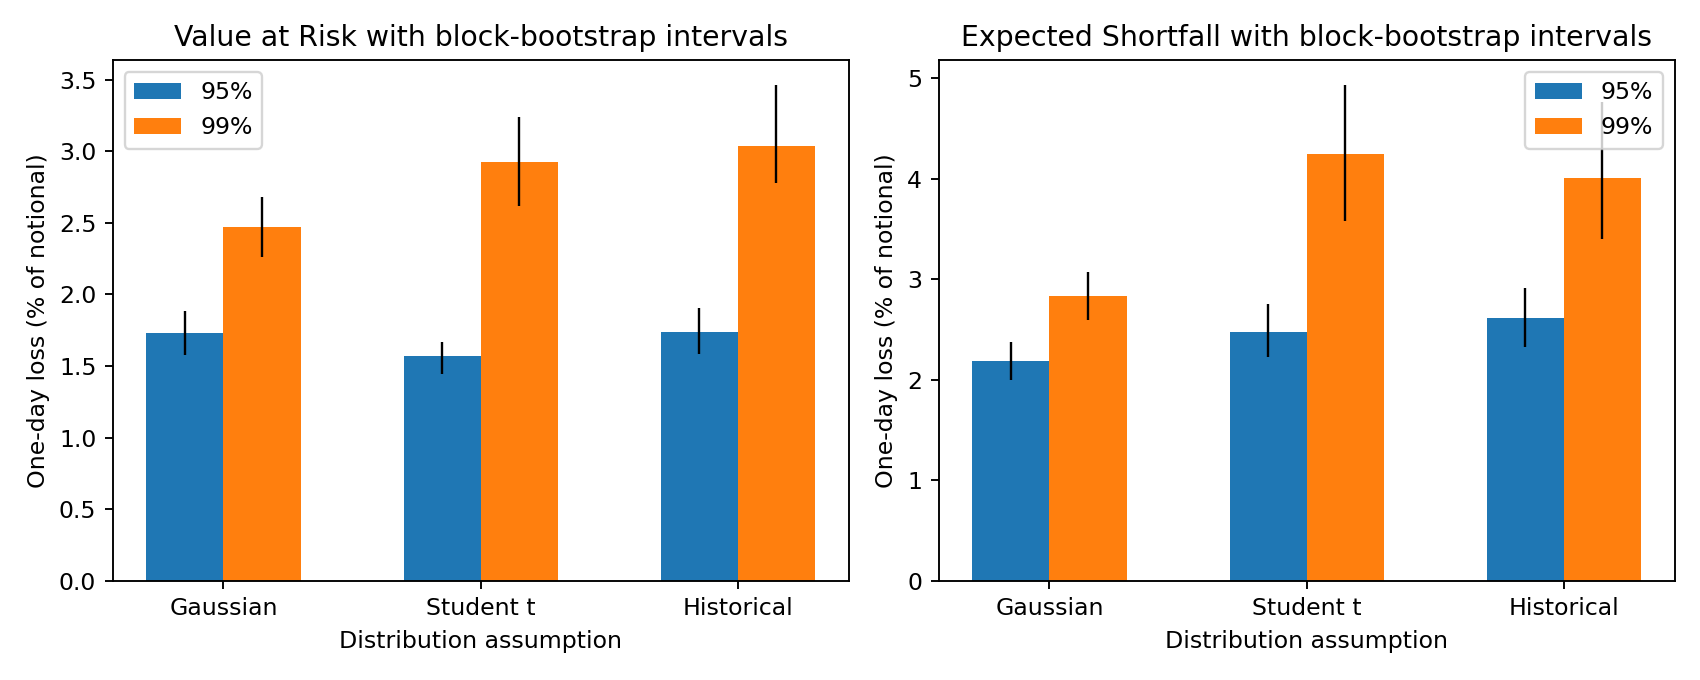

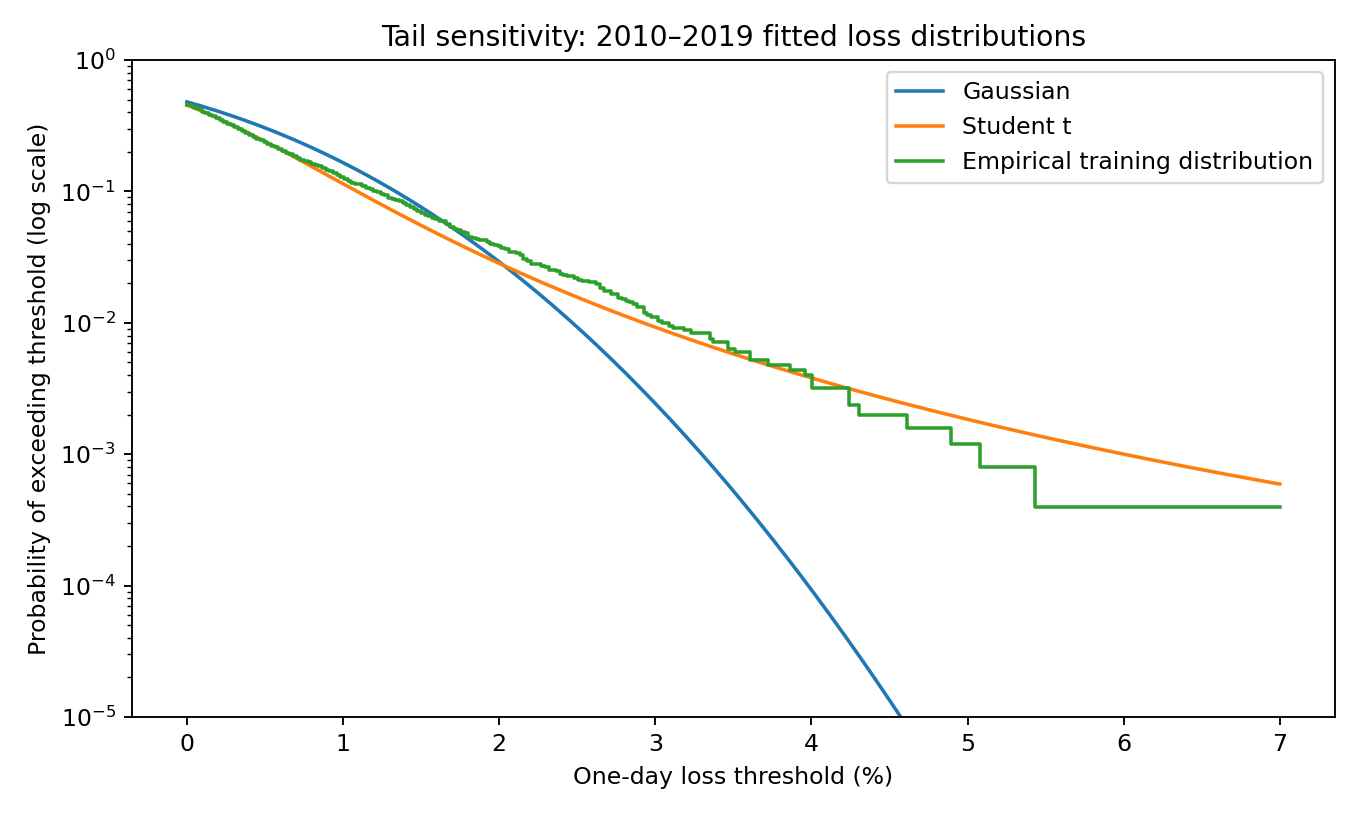

In [4]:
display(pd.read_csv(reports/'one_day_risk.csv').round(5))
display(Image(filename=str(reports/'figures/one_day_risk.png')))
display(Image(filename=str(reports/'figures/tail_comparison.png')))

## 4. Sensitivity to tail thickness and dependence
In a separate controlled calculation, t distributions with degrees of freedom 3, 5, 10 and 30 share the Gaussian fit's mean and variance. Their scale is adjusted to keep standard deviation constant. This distinguishes a tail-shape change from a change in volatility.

For the Gaussian model we also compare the observed sleeve covariance matrix with a hypothetical zero-correlation matrix having the same individual variances. Zero correlation is a counterfactual sensitivity assumption; it is not an estimate of this portfolio's actual dependence.

In [5]:
tail=pd.read_csv(reports/'tail_df_sensitivity.csv')
for col in ['var','es']:tail[col]*=100
display(tail.rename(columns={'var':'VaR_percent','es':'ES_percent'}).round(5))
corr=pd.read_csv(reports/'correlation_sensitivity.csv')
for col in ['sigma','var','es']:corr[col]*=100
display(corr.round(5))

,df,alpha,matched_mean,matched_sd,scale,VaR_percent,ES_percent
0,3,0.95,0.00054,0.01085,0.00626,1.41977,2.37207
1,3,0.99,0.00054,0.01085,0.00626,2.78936,4.33116
2,5,0.95,0.00054,0.01085,0.00840,1.63899,2.37411
3,5,0.99,0.00054,0.01085,0.00840,2.77297,3.68653
4,10,0.95,0.00054,0.01085,0.00970,1.70435,2.28242
5,10,0.99,0.00054,0.01085,0.00970,2.62713,3.20864
6,30,0.95,0.00054,0.01085,0.01048,1.72451,2.21563
7,30,0.99,0.00054,0.01085,0.01048,2.52079,2.94865


,assumption,alpha,sigma,var,es
0,Observed covariance,0.95,1.08451,1.73009,2.18327
1,Observed covariance,0.99,1.08451,2.46918,2.83668
2,Zero cross-sleeve correlation,0.95,0.46733,0.71492,0.91020
3,Zero cross-sleeve correlation,0.99,0.46733,1.03340,1.19177


## 5. Monte Carlo simulation and horizon assumptions
Simulate 200,000 paths at one- and ten-day horizons. Gaussian and Student t paths draw independent daily returns; historical iid paths sample empirical daily returns. A fourth ten-day simulation samples consecutive historical ten-day blocks to retain within-block dependence.

Ten-day loss is **minus the sum of daily returns**, a constant-notional additive P&L definition. It is not compounded buy-and-hold wealth. The sum of iid t variables is not generally t distributed, so no t square-root scaling rule is asserted.

Twenty simulation batches estimate Monte Carlo standard errors. These measure numerical simulation noise conditional on fitted parameters, and are separate from the bootstrap parameter intervals. Parametric draws are unbounded and do not impose physical simple-return limits; the additive P&L experiment is a model approximation.

In [6]:
mc=pd.read_csv(reports/'monte_carlo_risk.csv')
cols=['model','horizon_days','alpha','paths','var','es','var_mc_se','es_mc_se']
display(mc[cols].round(6))

,model,horizon_days,alpha,paths,var,es,var_mc_se,es_mc_se
0,Gaussian iid,1,0.95,200000,0.017329,0.021875,0.000055,0.000065
1,Gaussian iid,1,0.99,200000,0.024691,0.028386,0.000103,0.000153
2,Student t iid,1,0.95,200000,0.015749,0.024975,0.000061,0.000121
3,Student t iid,1,0.99,200000,0.029472,0.043087,0.000185,0.000436
4,Historical iid,1,0.95,200000,0.017367,0.026081,0.000060,0.000123
5,Historical iid,1,0.99,200000,0.030333,0.040107,0.000155,0.000316
6,Gaussian iid,10,0.95,200000,0.051178,0.065633,0.000145,0.000150
7,Gaussian iid,10,0.99,200000,0.074731,0.086343,0.000227,0.000361
8,Student t iid,10,0.95,200000,0.047799,0.067770,0.000167,0.000305
9,Student t iid,10,0.99,200000,0.078222,0.101744,0.000363,0.001008


## 6. Chronological out-of-sample forecasts
Two schemes forecast the same 1,258 trading days:

1. **Frozen:** fit only on 2010–2019 and hold the risk thresholds fixed.
2. **Rolling:** use the preceding 750 trading days and refit on each month's first trading day, then hold thresholds until the next refit.

Each rolling fit ends strictly before its first forecast date. Both schemes use predeclared settings. Frozen and rolling comparisons change both recency and sample length, so differences cannot be attributed solely to one mechanism. The snapshot may include revised historical data; this is not a vintage-data trading simulation.

,date,scheme,model,alpha,loss,var,es,exceeded,fit_start,fit_end
0,2020-01-02,Frozen 2010–2019,Gaussian,0.95,-0.003333,0.017301,0.021833,False,2010-01-04,2019-12-31
1,2020-01-02,Frozen 2010–2019,Gaussian,0.99,-0.003333,0.024692,0.028367,False,2010-01-04,2019-12-31
2,2020-01-02,Frozen 2010–2019,Student t,0.95,-0.003333,0.015701,0.024804,False,2010-01-04,2019-12-31
3,2020-01-02,Frozen 2010–2019,Student t,0.99,-0.003333,0.029225,0.042488,False,2010-01-04,2019-12-31
4,2020-01-02,Frozen 2010–2019,Historical,0.95,-0.003333,0.017367,0.026117,False,2010-01-04,2019-12-31


,refit_date,fit_start,fit_end,observations,mean,sigma,t_df,t_location,t_scale,t_optimizer_success
0,2020-01-02,2017-01-09,2019-12-31,750,0.00044,0.00894,3.56493,0.00089,0.00620,True
1,2020-02-03,2017-02-08,2020-01-31,750,0.00040,0.00896,3.45279,0.00089,0.00614,True
2,2020-03-02,2017-03-08,2020-02-28,750,0.00025,0.00925,3.25220,0.00087,0.00617,True
3,2020-04-01,2017-04-07,2020-03-31,750,0.00002,0.01412,2.10322,0.00089,0.00594,True
4,2020-05-01,2017-05-09,2020-04-30,750,0.00019,0.01514,2.05000,0.00096,0.00623,True


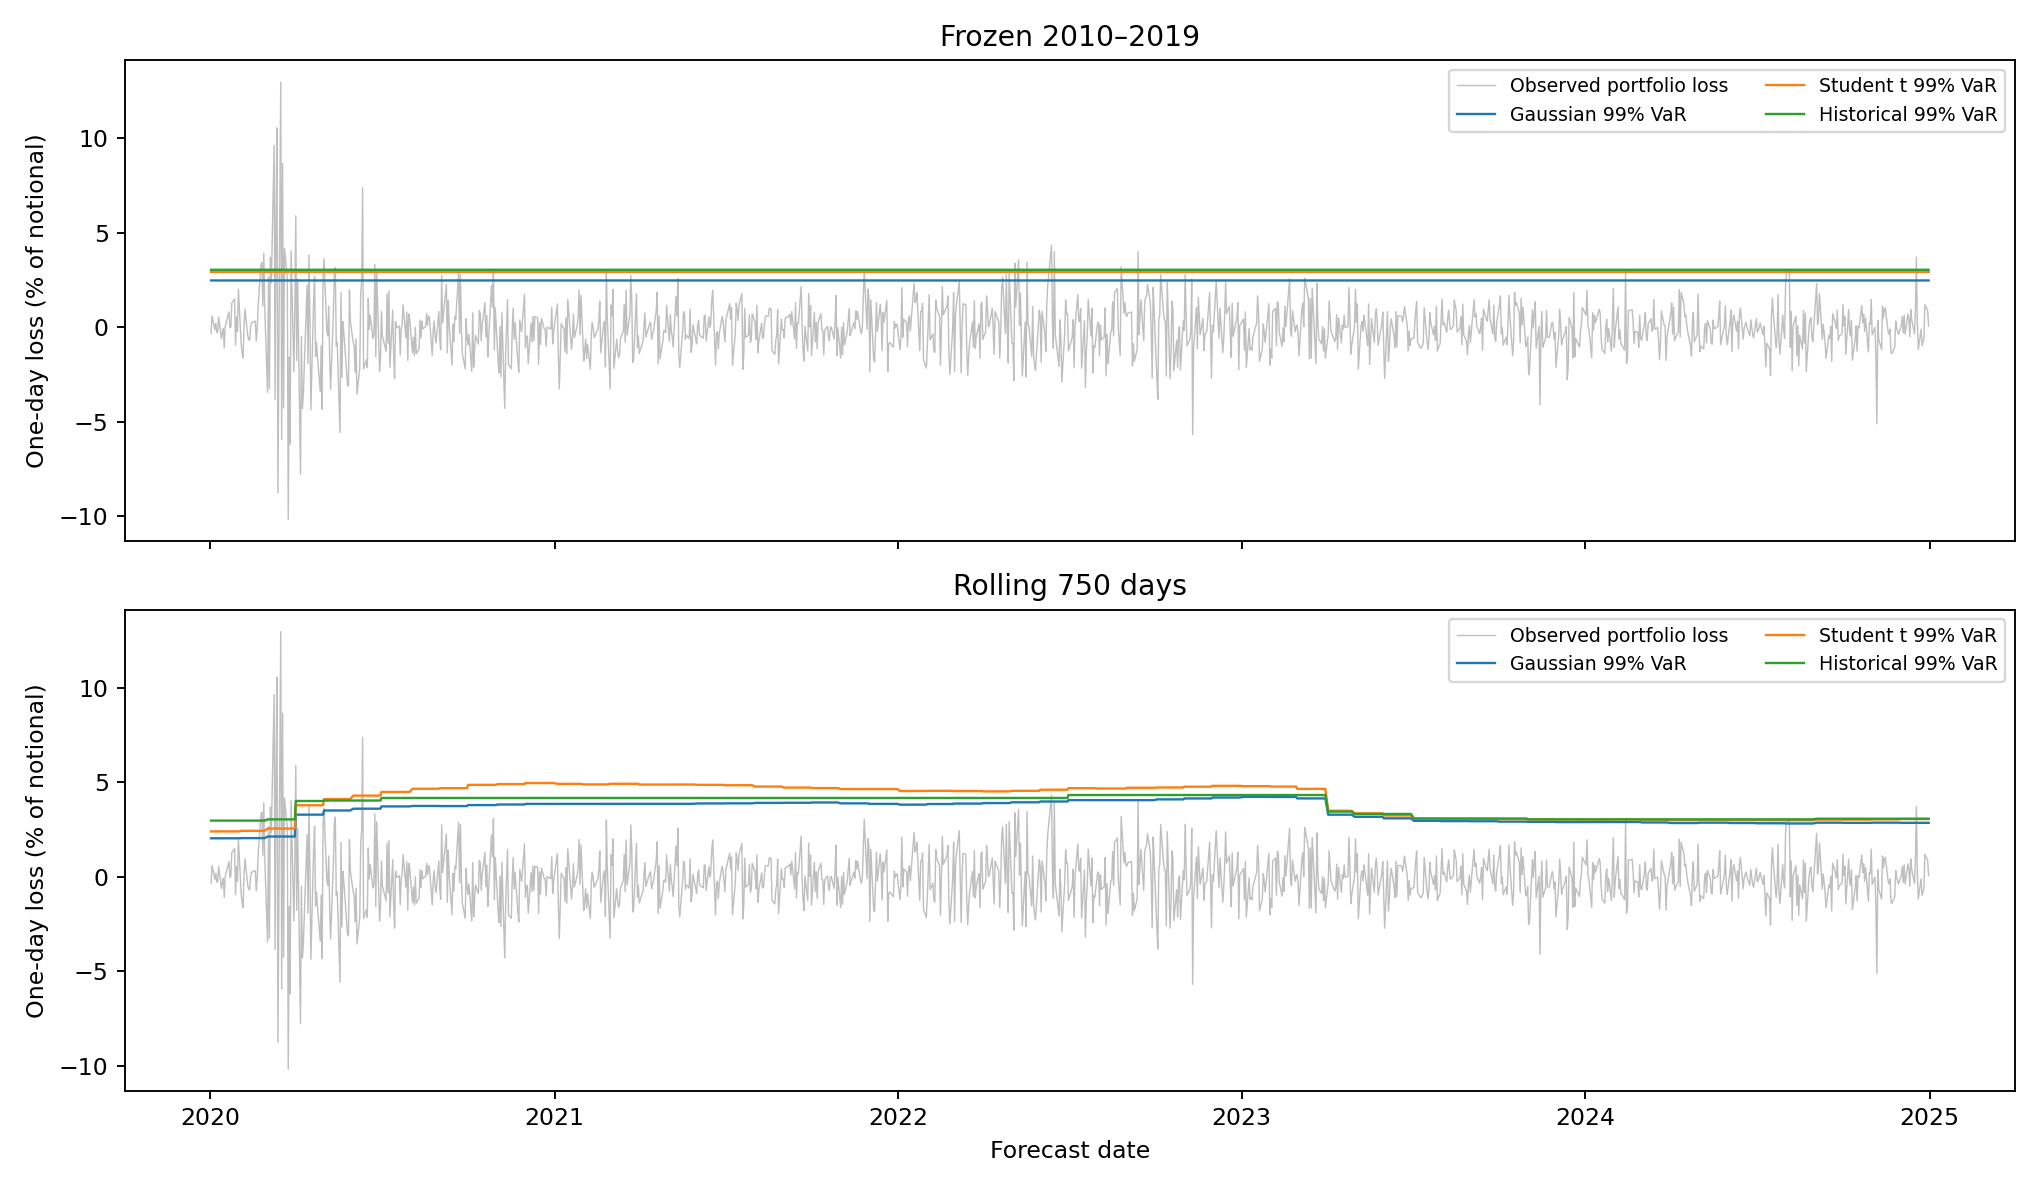

In [7]:
forecasts=pd.read_csv(reports/'forecasts.csv',parse_dates=['date','fit_end'])
assert (forecasts.fit_end<forecasts.date).all()
display(forecasts.head())
display(pd.read_csv(reports/'rolling_fit_parameters.csv').head().round(5))
display(Image(filename=str(reports/'figures/var_backtest.png')))

## 7. Backtesting and uncertainty
A 99% VaR forecasts a loss exceedance probability of 1%. We report exceedance counts, exact binomial coverage tests and rate intervals, Kupiec likelihood-ratio coverage tests, a first-order exceedance-independence test, and average quantile loss (lower is better).

Binomial and asymptotic test interpretations rely on assumptions about independent, correctly calibrated hits. Observed clustering makes nominal p-values less reliable; sparse extreme-tail transitions also limit independence-test power. Multiple comparisons are exploratory, not adjusted.

Mean realized losses and mean predicted ES on VaR-exceedance days are **descriptive severity checks only**. This is not a formal joint VaR/ES backtest or regulatory certification.

In [8]:
summary=pd.read_csv(reports/'backtest_summary.csv',dtype={'period':str})
cols=['scheme','model','alpha','n','exceedances','expected_exceedances','exceedance_rate','binomial_pvalue','independence_pvalue','mean_quantile_loss']
display(summary[summary.period=='2020–2024'][cols].round(6))
display(summary[(summary.alpha==.99)&(summary.period!='2020–2024')][['scheme','model','period','n','exceedances','exceedance_rate']])

,scheme,model,alpha,n,exceedances,expected_exceedances,exceedance_rate,binomial_pvalue,independence_pvalue,mean_quantile_loss
0,Frozen 2010–2019,Gaussian,0.95,1258,106,62.90,0.084261,0.000000,0.017877,0.001916
6,Frozen 2010–2019,Gaussian,0.99,1258,52,12.58,0.041335,0.000000,0.005176,0.000836
12,Frozen 2010–2019,Historical,0.95,1258,105,62.90,0.083466,0.000001,0.014781,0.001913
18,Frozen 2010–2019,Historical,0.99,1258,28,12.58,0.022258,0.000154,0.152143,0.000714
24,Frozen 2010–2019,Student t,0.95,1258,120,62.90,0.095390,0.000000,0.044802,0.001981
30,Frozen 2010–2019,Student t,0.99,1258,30,12.58,0.023847,0.000022,0.198066,0.000729
36,Rolling 750 days,Gaussian,0.95,1258,50,62.90,0.039746,0.105334,0.000089,0.001922
42,Rolling 750 days,Gaussian,0.99,1258,24,12.58,0.019078,0.003939,0.000002,0.000802
48,Rolling 750 days,Historical,0.95,1258,57,62.90,0.045310,0.477080,0.000024,0.001911
54,Rolling 750 days,Historical,0.99,1258,16,12.58,0.012719,0.318842,0.014529,0.000721


,scheme,model,period,n,exceedances,exceedance_rate
7,Frozen 2010–2019,Gaussian,2020,253,28,0.110672
8,Frozen 2010–2019,Gaussian,2021,252,4,0.015873
9,Frozen 2010–2019,Gaussian,2022,251,14,0.055777
10,Frozen 2010–2019,Gaussian,2023,250,2,0.008000
11,Frozen 2010–2019,Gaussian,2024,252,4,0.015873
19,Frozen 2010–2019,Historical,2020,253,18,0.071146
20,Frozen 2010–2019,Historical,2021,252,1,0.003968
21,Frozen 2010–2019,Historical,2022,251,7,0.027888
22,Frozen 2010–2019,Historical,2023,250,0,0.000000
23,Frozen 2010–2019,Historical,2024,252,2,0.007937


## 8. Interpretation and limitations
Fitted 99% one-day ES is approximately 2.84% under Gaussian assumptions and 4.25% under Student t. At 95%, t VaR is lower than Gaussian VaR: greater tail thickness does not raise every quantile.

Frozen Gaussian 99% VaR has 52 exceedances rather than the expected 12.58. Frozen t and historical forecasts also exceed their nominal rate. Rolling estimates improve aggregate coverage, while clustered losses remain a warning about iid and unconditional-distribution assumptions. Failure to reject coverage is not proof of validity.

The exercise combines probability distributions, constrained likelihood estimation, covariance, Monte Carlo methods, uncertainty quantification and temporal validation.

Limitations include symmetric parametric distributions despite negative skew, within-equity dependence, a single portfolio and historical snapshot, fixed block length and lookback, monthly adaptation, transaction costs omitted, and no GARCH/conditional-volatility model. Parameter intervals do not predict unobserved crises. The ten-day experiment is not backtested, and formal ES backtesting remains an extension.

In [9]:
display(json.loads((reports/'run_metadata.json').read_text()))

{'run_time_utc': '2026-10-11T17:33:49.507382+00:00',
 'seed': 2026,
 'bootstrap_replicates': 250,
 'bootstrap_block_length': 10,
 'monte_carlo_paths': 200000,
 'rolling_window': 750,
 'rolling_refits': 60,
 'train_dates': ['2010-01-01', '2019-12-31'],
 'test_dates': ['2020-01-01', '2024-12-31'],
 'weights': [0.16666666666666666,
  0.16666666666666666,
  0.16666666666666666,
  0.16666666666666666,
  0.16666666666666666,
  0.16666666666666666],
 'audit': {'raw_daily_rows': 26317,
  'selected_complete_rows': 3774,
  'missing_rows_removed': 0,
  'source_header': 'This file was created by using the 202608 CRSP database.'},
 'python': '3.12.7',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'scipy': '1.13.1',
 'matplotlib': '3.9.2',
 'raw_sha256': '5c520575d3f0321fc2a9fe98695f1aaf5ceeb573d60385265bc0b85c13f5daa0',
 'source_url': 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/6_Portfolios_2x3_daily_CSV.zip'}